# Repeated 80/20 robustness run: statistical and visual inspection

This notebook audits and summarizes the outputs produced by `06.robustness/run_after_jobs.sh`.

It is designed for the folder layout:

```text
06.robustness/
├── notebooks/
│   └── 01_inspect_robustness_results.ipynb
└── results/
    ├── metrics/metrics_long.parquet   # or .csv.gz / .tsv.gz
    ├── split_manifest/repeated_8020_splits.tsv
    └── cascade/
        ├── bootstrap_metric_ci.tsv
        ├── paired_gain_tests.tsv
        ├── robust_cascade_atlas.tsv
        └── robust_cascade_counts.tsv
```

### Statistical interpretation

The 20 repeats are **20 repeated 80/20 train–test partitions**, not 20 bootstrap samples. Each per-split Pearson correlation is based on roughly 74 held-out CCLE samples. The `N_BOOT=500` step bootstraps the **20 split-level metric values** to summarize their median and median model gain. Because repeated holdouts overlap, those 20 values are not fully independent. Treat the resulting confidence intervals as **descriptive stability intervals**, not as definitive hypothesis-test confidence intervals.

This notebook therefore emphasizes:

- median and interquartile range across splits;
- pass rate across splits;
- model-gain consistency;
- sensitivity to correlation and pass-rate thresholds;
- calibration and error metrics;
- incomplete tasks, failed proteins, and suspicious outputs.

For a final inferential claim, pair this stability analysis with full-sample out-of-fold predictions from LOO or repeated grouped cross-validation.

In [3]:
from __future__ import annotations

import json
import math
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Resolve the project folder whether the notebook is launched from the project root
# or from 06.robustness/notebooks/.
CWD = Path.cwd().resolve()
if (CWD / "results").exists():
    PROJECT_DIR = CWD
elif (CWD.parent / "results").exists():
    PROJECT_DIR = CWD.parent
else:
    PROJECT_DIR = CWD.parent if CWD.name == "notebooks" else CWD

RESULTS_DIR = Path(os.environ.get("ROBUSTNESS_RESULTS_DIR", PROJECT_DIR / "results")).resolve()
INSPECTION_DIR = RESULTS_DIR / "inspection"
FIGURE_DIR = INSPECTION_DIR / "figures"
TABLE_DIR = INSPECTION_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Selected configurations used in run_after_jobs.sh.
PROXY_CONFIG = ("proxy", "zscore", 0)
ENET_CONFIG = ("enet", "zscore", 2000)
XGB_CONFIG = None  # Example: ("xgb", "zscore", 2000)

PRIMARY_METRIC = "pearson"
PRIMARY_THRESHOLD = 0.50
PRIMARY_PASS_RATE = 0.80
GAIN_THRESHOLD = 0.05

# Visual inspection parameters.
TOP_N = 25
RANDOM_SEED = 42
SAVE_PNG = True
SAVE_PDF = True
SAVE_SVG = True

CLASS_ORDER = [
    "robust_proxy_sufficient",
    "robust_linear_improvable",
    "robust_nonlinear_improvable",
    "unstable_or_borderline",
    "unresolved",
]
CLASS_LABELS = {
    "robust_proxy_sufficient": "Proxy sufficient",
    "robust_linear_improvable": "Linear improvable",
    "robust_nonlinear_improvable": "Nonlinear improvable",
    "unstable_or_borderline": "Unstable / borderline",
    "unresolved": "Unresolved",
}
CLASS_COLORS = {
    "robust_proxy_sufficient": "#0072B2",
    "robust_linear_improvable": "#009E73",
    "robust_nonlinear_improvable": "#E69F00",
    "unstable_or_borderline": "#CC79A7",
    "unresolved": "#7F7F7F",
}
MODEL_LABELS = {"proxy": "Same-gene linear proxy", "enet": "ElasticNet", "xgb": "XGBoost"}

print(f"PROJECT_DIR:   {PROJECT_DIR}")
print(f"RESULTS_DIR:   {RESULTS_DIR}")
print(f"INSPECTION_DIR:{INSPECTION_DIR}")

PROJECT_DIR:   C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness
RESULTS_DIR:   C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results
INSPECTION_DIR:C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\inspection


## 1. Load outputs and verify the run

In [4]:
def read_table_any(candidates: list[Path], required: bool = True) -> tuple[pd.DataFrame | None, Path | None]:
    for path in candidates:
        if not path.exists():
            continue
        if path.suffix == ".parquet":
            return pd.read_parquet(path), path
        if path.name.endswith(".tsv.gz") or path.suffix == ".tsv":
            return pd.read_csv(path, sep="\t"), path
        return pd.read_csv(path), path
    if required:
        raise FileNotFoundError("None of these files exists:\n" + "\n".join(map(str, candidates)))
    return None, None


def save_current_figure(name: str) -> None:
    name = re.sub(r"[^A-Za-z0-9_.-]+", "_", name).strip("_")
    if SAVE_PNG:
        plt.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", dpi=300)
    if SAVE_PDF:
        plt.savefig(FIGURE_DIR / f"{name}.pdf", bbox_inches="tight")
    if SAVE_SVG:
        plt.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")


def select_config(df: pd.DataFrame, config: tuple[str, str, int] | None) -> pd.DataFrame:
    if config is None:
        return pd.DataFrame(columns=df.columns)
    model, normalization, select_k = config
    return df.loc[
        df["model"].astype(str).str.lower().eq(model.lower())
        & df["normalization"].astype(str).str.lower().eq(normalization.lower())
        & pd.to_numeric(df["select_k"], errors="coerce").eq(int(select_k))
    ].copy()


metrics, metrics_path = read_table_any([
    RESULTS_DIR / "metrics" / "metrics_long.parquet",
    RESULTS_DIR / "metrics" / "metrics_long.csv.gz",
    RESULTS_DIR / "metrics" / "metrics_long.tsv.gz",
])
atlas, atlas_path = read_table_any([RESULTS_DIR / "cascade" / "robust_cascade_atlas.tsv"])
counts_saved, counts_path = read_table_any([RESULTS_DIR / "cascade" / "robust_cascade_counts.tsv"])
metric_ci, metric_ci_path = read_table_any([RESULTS_DIR / "cascade" / "bootstrap_metric_ci.tsv"])
gains, gains_path = read_table_any([RESULTS_DIR / "cascade" / "paired_gain_tests.tsv"])
split_manifest, split_path = read_table_any(
    [RESULTS_DIR / "split_manifest" / "repeated_8020_splits.tsv"], required=False
)

print("Loaded:")
for label, path, df in [
    ("metrics", metrics_path, metrics),
    ("atlas", atlas_path, atlas),
    ("counts", counts_path, counts_saved),
    ("metric CIs", metric_ci_path, metric_ci),
    ("paired gains", gains_path, gains),
    ("split manifest", split_path, split_manifest),
]:
    print(f"  {label:16s} {str(path):80s} shape={None if df is None else df.shape}")

metrics["split_id"] = pd.to_numeric(metrics["split_id"], errors="coerce").astype("Int64")
metrics["select_k"] = pd.to_numeric(metrics["select_k"], errors="coerce").astype("Int64")
for col in [
    "pearson", "spearman", "mse", "rmse", "nrmse", "r2", "cosine",
    "calibration_slope", "calibration_intercept", "pred_sd", "obs_sd",
    "sd_ratio", "n_test", "n_train", "best_cv_mse", "n_selected_features",
    "n_nonzero_features",
]:
    if col in metrics.columns:
        metrics[col] = pd.to_numeric(metrics[col], errors="coerce")

selected_frames = {
    "proxy": select_config(metrics, PROXY_CONFIG),
    "enet": select_config(metrics, ENET_CONFIG),
}
if XGB_CONFIG is not None:
    selected_frames["xgb"] = select_config(metrics, XGB_CONFIG)
selected_metrics = pd.concat(selected_frames.values(), ignore_index=True)

available_configs = (
    metrics[["model", "normalization", "select_k"]]
    .drop_duplicates()
    .sort_values(["model", "normalization", "select_k"])
    .reset_index(drop=True)
)
display(Markdown("### Available model configurations"))
display(available_configs)

for label, frame in selected_frames.items():
    if frame.empty:
        warnings.warn(f"No rows found for selected {label} configuration.")
    else:
        print(
            f"{label:6s}: rows={len(frame):,}; proteins={frame['protein'].nunique():,}; "
            f"splits={frame['split_id'].nunique():,}"
        )

Loaded:
  metrics          C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\metrics\metrics_long.parquet shape=(14760, 28)
  atlas            C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\cascade\robust_cascade_atlas.tsv shape=(369, 24)
  counts           C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\cascade\robust_cascade_counts.tsv shape=(3, 2)
  metric CIs       C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\cascade\bootstrap_metric_ci.tsv shape=(738, 9)
  paired gains     C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\cascade\paired_gain_tests.tsv shape=(369, 7)
  split manifest   C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\split_manifest\repeated_8020_splits.tsv shape=(96860, 3)


### Available model configurations

,model,normalization,select_k
0,enet,zscore,2000
1,proxy,zscore,0


proxy : rows=7,380; proteins=369; splits=20
enet  : rows=7,380; proteins=369; splits=20


In [5]:
# Integrity and completeness checks.
expected_splits = int(metrics["split_id"].nunique())
if split_manifest is not None:
    manifest_splits = int(split_manifest["split_id"].nunique())
    split_sizes = (
        split_manifest.groupby(["split_id", "set"]).size().unstack(fill_value=0)
        .rename_axis(None, axis=1)
    )
    print(f"Manifest splits: {manifest_splits}")
    display(split_sizes.describe().T)
else:
    manifest_splits = expected_splits
    split_sizes = None

integrity_rows = []
for label, frame in selected_frames.items():
    if frame.empty:
        continue
    duplicate_count = int(frame.duplicated(["split_id", "protein"]).sum())
    split_counts = frame.groupby("protein")["split_id"].nunique()
    integrity_rows.append({
        "model": label,
        "rows": len(frame),
        "proteins": frame["protein"].nunique(),
        "splits": frame["split_id"].nunique(),
        "duplicate protein-split rows": duplicate_count,
        "proteins with all splits": int((split_counts == manifest_splits).sum()),
        "proteins missing >=1 split": int((split_counts < manifest_splits).sum()),
        "minimum splits per protein": int(split_counts.min()),
        "median splits per protein": float(split_counts.median()),
        "maximum splits per protein": int(split_counts.max()),
    })
integrity = pd.DataFrame(integrity_rows)
display(integrity)
integrity.to_csv(TABLE_DIR / "run_integrity_summary.tsv", sep="\t", index=False)

if any(integrity.get("duplicate protein-split rows", pd.Series(dtype=int)) > 0):
    warnings.warn("Duplicate protein-split rows were found. Inspect task reruns or overlapping shards before interpretation.")
if any(integrity.get("proteins missing >=1 split", pd.Series(dtype=int)) > 0):
    warnings.warn("Some proteins do not have all expected repeated splits. Use n_splits_valid when interpreting pass rates.")

Manifest splits: 20


,count,mean,std,min,25%,50%,75%,max
test,20.0000,969.0000,0.0000,969.0000,969.0000,969.0000,969.0000,969.0000
train,20.0000,"3,874.0000",0.0000,"3,874.0000","3,874.0000","3,874.0000","3,874.0000","3,874.0000"


,model,rows,proteins,splits,duplicate protein-split rows,proteins with all splits,proteins missing >=1 split,minimum splits per protein,median splits per protein,maximum splits per protein
0,proxy,7380,369,20,0,369,0,20,20.0000,20
1,enet,7380,369,20,0,369,0,20,20.0000,20


## 2. Failures, missing metrics, and test-set sizes

A statistically attractive summary can still be invalid if many proteins silently failed, have constant predictions, or have fewer valid test samples. This section checks those failure modes first.

,model,status,n_rows,fraction_within_model
0,enet,ok,7380,1.0000
1,proxy,ok,7380,1.0000


,model,rows,finite_pearson,missing_fraction_pearson,finite_spearman,missing_fraction_spearman,finite_nrmse,missing_fraction_nrmse,finite_r2,missing_fraction_r2,finite_calibration_slope,missing_fraction_calibration_slope,finite_sd_ratio,missing_fraction_sd_ratio,median_n_test,min_n_test,max_n_test
0,proxy,7380,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,969.0000,969.0000,969.0000
1,enet,7380,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,7380,0.0000,969.0000,969.0000,969.0000


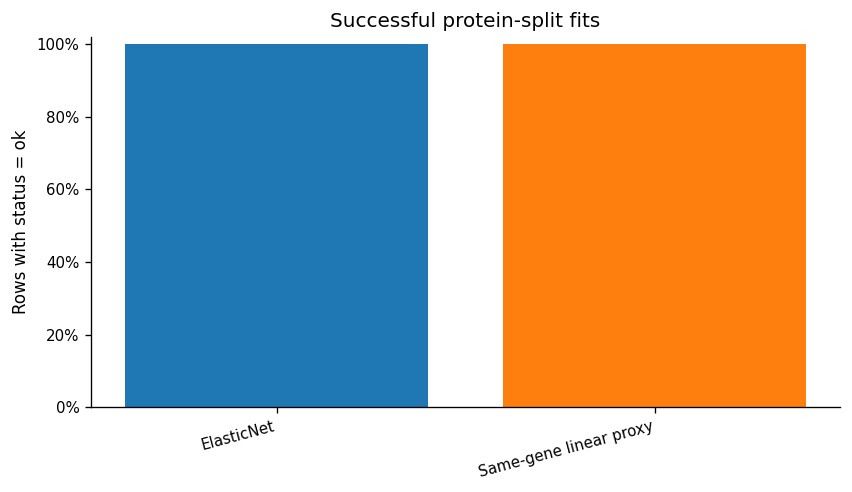

In [6]:
status_summary = (
    selected_metrics.assign(status=selected_metrics.get("status", "missing").fillna("missing"))
    .groupby(["model", "status"], dropna=False)
    .size()
    .reset_index(name="n_rows")
)
status_summary["fraction_within_model"] = status_summary["n_rows"] / status_summary.groupby("model")["n_rows"].transform("sum")
display(status_summary.sort_values(["model", "n_rows"], ascending=[True, False]).head(30))
status_summary.to_csv(TABLE_DIR / "status_summary.tsv", sep="\t", index=False)

metric_quality_rows = []
for label, frame in selected_frames.items():
    if frame.empty:
        continue
    row = {"model": label, "rows": len(frame)}
    for col in ["pearson", "spearman", "nrmse", "r2", "calibration_slope", "sd_ratio"]:
        if col in frame:
            row[f"finite_{col}"] = int(np.isfinite(frame[col]).sum())
            row[f"missing_fraction_{col}"] = float(1 - np.isfinite(frame[col]).mean())
    row["median_n_test"] = float(frame["n_test"].median()) if "n_test" in frame else np.nan
    row["min_n_test"] = float(frame["n_test"].min()) if "n_test" in frame else np.nan
    row["max_n_test"] = float(frame["n_test"].max()) if "n_test" in frame else np.nan
    metric_quality_rows.append(row)
metric_quality = pd.DataFrame(metric_quality_rows)
display(metric_quality)
metric_quality.to_csv(TABLE_DIR / "metric_quality_summary.tsv", sep="\t", index=False)

plt.figure(figsize=(7.2, 4.2))
status_plot = status_summary.copy()
status_plot["label"] = status_plot["model"].map(MODEL_LABELS).fillna(status_plot["model"])
for i, (model, group) in enumerate(status_plot.groupby("label", sort=False)):
    ok_fraction = group.loc[group["status"].eq("ok"), "fraction_within_model"].sum()
    plt.bar(i, ok_fraction)
plt.xticks(range(status_plot["label"].nunique()), status_plot["label"].drop_duplicates(), rotation=15, ha="right")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0, 1.02)
plt.ylabel("Rows with status = ok")
plt.title("Successful protein-split fits")
plt.tight_layout()
save_current_figure("01_successful_fit_fraction")
plt.show()

## 3. Overall repeated-split performance summaries

,model,proteins,splits,median protein median pearson,Q25 protein median pearson,Q75 protein median pearson,median protein median spearman,Q25 protein median spearman,Q75 protein median spearman,median protein median nrmse,Q25 protein median nrmse,Q75 protein median nrmse,median protein median r2,Q25 protein median r2,Q75 protein median r2,median protein median calibration_slope,Q25 protein median calibration_slope,Q75 protein median calibration_slope,median protein median calibration_intercept,Q25 protein median calibration_intercept,Q75 protein median calibration_intercept,median protein median sd_ratio,Q25 protein median sd_ratio,Q75 protein median sd_ratio,proteins pass rate >= 0.80,fraction proteins pass rate >= 0.80
0,Same-gene linear proxy,369,20,0.3122,0.2536,0.3762,0.2749,0.2140,0.3341,0.9500,0.9268,0.9673,0.0966,0.0633,0.1402,1.0069,0.9863,1.0347,-0.0010,-0.0052,0.0039,0.3123,0.2494,0.3743,2,0.0054
1,ElasticNet,369,20,0.7016,0.6546,0.7410,0.6240,0.5727,0.6677,0.7146,0.6744,0.7577,0.4888,0.4253,0.5447,1.0463,1.0297,1.0634,-0.0007,-0.0053,0.0036,0.6722,0.6302,0.7113,362,0.9810


C:\Users\hp\AppData\Local\Temp\ipykernel_5724\1376852062.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


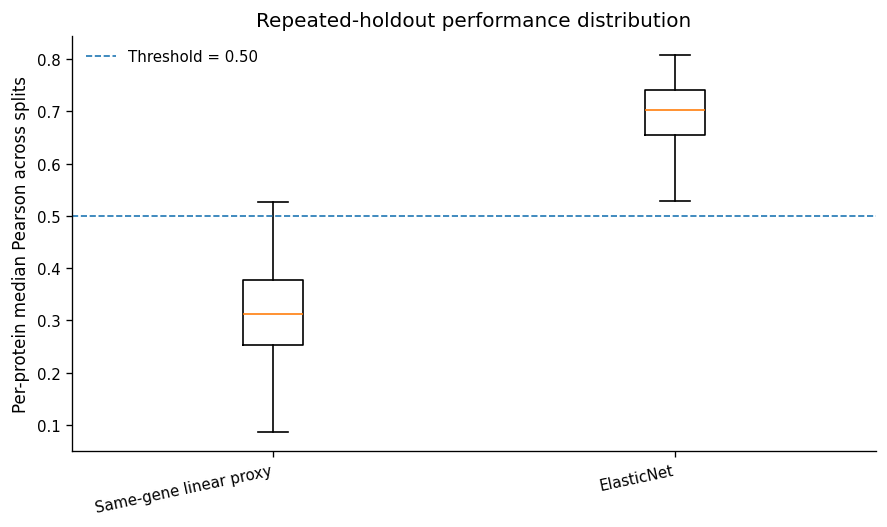

In [7]:
def summarize_repeated_metrics(frame: pd.DataFrame, model_label: str) -> dict:
    result = {"model": model_label, "proteins": frame["protein"].nunique(), "splits": frame["split_id"].nunique()}
    for metric in ["pearson", "spearman", "nrmse", "r2", "calibration_slope", "calibration_intercept", "sd_ratio"]:
        if metric not in frame:
            continue
        per_protein = frame.groupby("protein")[metric].median()
        result[f"median protein median {metric}"] = float(per_protein.median())
        result[f"Q25 protein median {metric}"] = float(per_protein.quantile(0.25))
        result[f"Q75 protein median {metric}"] = float(per_protein.quantile(0.75))
    if PRIMARY_METRIC in frame:
        protein_pass = frame.groupby("protein")[PRIMARY_METRIC].apply(lambda x: np.nanmean(pd.to_numeric(x, errors="coerce") >= PRIMARY_THRESHOLD))
        result[f"proteins pass rate >= {PRIMARY_PASS_RATE:.2f}"] = int((protein_pass >= PRIMARY_PASS_RATE).sum())
        result[f"fraction proteins pass rate >= {PRIMARY_PASS_RATE:.2f}"] = float((protein_pass >= PRIMARY_PASS_RATE).mean())
    return result

overall_summary = pd.DataFrame([
    summarize_repeated_metrics(frame, MODEL_LABELS.get(label, label))
    for label, frame in selected_frames.items() if not frame.empty
])
display(overall_summary)
overall_summary.to_csv(TABLE_DIR / "overall_model_summary.tsv", sep="\t", index=False)

# Per-protein medians for downstream plots.
protein_summaries = {}
for label, frame in selected_frames.items():
    if frame.empty:
        continue
    agg_map = {}
    for metric in ["pearson", "spearman", "nrmse", "r2", "calibration_slope", "calibration_intercept", "sd_ratio"]:
        if metric in frame:
            agg_map[f"{metric}_median"] = (metric, "median")
            agg_map[f"{metric}_q25"] = (metric, lambda x: np.nanquantile(x, 0.25))
            agg_map[f"{metric}_q75"] = (metric, lambda x: np.nanquantile(x, 0.75))
    summary = frame.groupby("protein").agg(**agg_map).reset_index()
    summary[f"{PRIMARY_METRIC}_pass_rate"] = frame.groupby("protein")[PRIMARY_METRIC].apply(
        lambda x: np.nanmean(pd.to_numeric(x, errors="coerce") >= PRIMARY_THRESHOLD)
    ).values
    protein_summaries[label] = summary

# Distribution of per-protein median Pearson.
plt.figure(figsize=(7.5, 4.5))
labels, data = [], []
for label in ["proxy", "enet", "xgb"]:
    if label not in protein_summaries:
        continue
    labels.append(MODEL_LABELS.get(label, label))
    data.append(protein_summaries[label][f"{PRIMARY_METRIC}_median"].dropna().values)
plt.boxplot(data, labels=labels, showfliers=False)
plt.axhline(PRIMARY_THRESHOLD, linestyle="--", linewidth=1, label=f"Threshold = {PRIMARY_THRESHOLD:.2f}")
plt.ylabel(f"Per-protein median {PRIMARY_METRIC.title()} across splits")
plt.title("Repeated-holdout performance distribution")
plt.legend(frameon=False)
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
save_current_figure("02_per_protein_median_pearson_boxplot")
plt.show()

## 4. Robust cascade composition

,robust_class,n_proteins,fraction,label
0,robust_proxy_sufficient,2,0.0054,Proxy sufficient
1,robust_linear_improvable,360,0.9756,Linear improvable
2,robust_nonlinear_improvable,0,0.0000,Nonlinear improvable
3,unstable_or_borderline,7,0.0190,Unstable / borderline
4,unresolved,0,0.0000,Unresolved


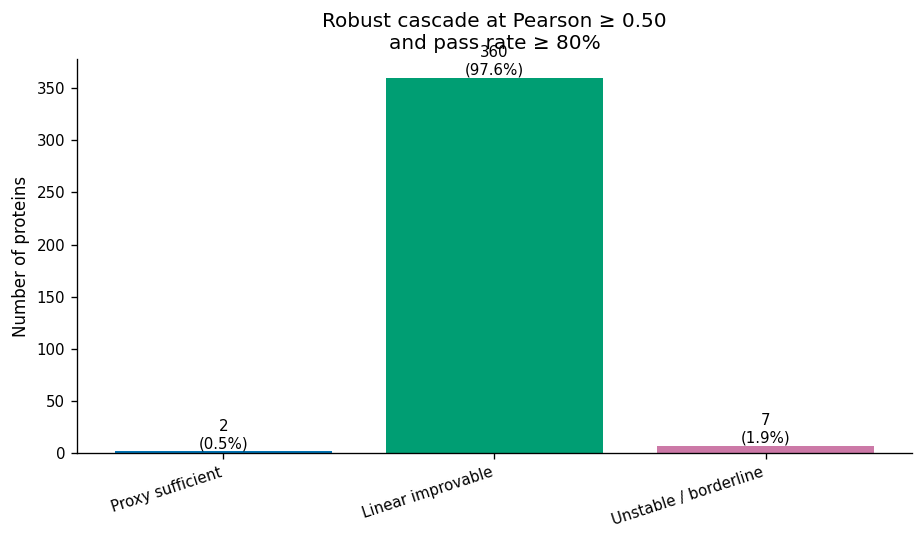

In [8]:
atlas["robust_class"] = atlas["robust_class"].astype(str)
class_counts = (
    atlas["robust_class"].value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename_axis("robust_class")
    .reset_index(name="n_proteins")
)
class_counts["fraction"] = class_counts["n_proteins"] / class_counts["n_proteins"].sum()
class_counts["label"] = class_counts["robust_class"].map(CLASS_LABELS)
display(class_counts)
class_counts.to_csv(TABLE_DIR / "robust_class_counts_with_fractions.tsv", sep="\t", index=False)

plt.figure(figsize=(7.8, 4.6))
valid = class_counts.loc[class_counts["n_proteins"] > 0].copy()
bars = plt.bar(
    valid["label"], valid["n_proteins"],
    color=[CLASS_COLORS[c] for c in valid["robust_class"]]
)
for bar, n, fraction in zip(bars, valid["n_proteins"], valid["fraction"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{n:,}\n({fraction:.1%})", ha="center", va="bottom", fontsize=9)
plt.ylabel("Number of proteins")
plt.title(f"Robust cascade at {PRIMARY_METRIC.title()} ≥ {PRIMARY_THRESHOLD:.2f}\nand pass rate ≥ {PRIMARY_PASS_RATE:.0%}")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
save_current_figure("03_robust_cascade_counts")
plt.show()

## 5. Proxy versus ElasticNet: performance, stability, and gain

Proxy columns: ['proxy_n_splits_valid', 'proxy_median_pearson', 'proxy_ci_low', 'proxy_ci_high', 'proxy_q25', 'proxy_q75', 'proxy_pass_rate']
ENet columns: ['enet_n_splits_valid', 'enet_median_pearson', 'enet_ci_low', 'enet_ci_high', 'enet_q25', 'enet_q75', 'enet_pass_rate', 'enet_vs_proxy_n_splits_valid', 'enet_vs_proxy_median_delta', 'enet_vs_proxy_ci_low', 'enet_vs_proxy_ci_high', 'enet_vs_proxy_fraction_delta_gt_0']


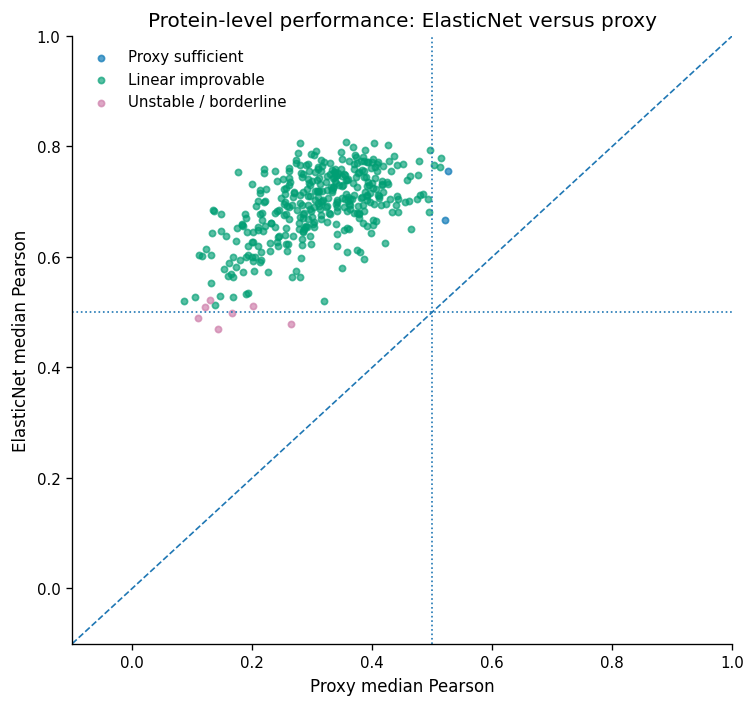

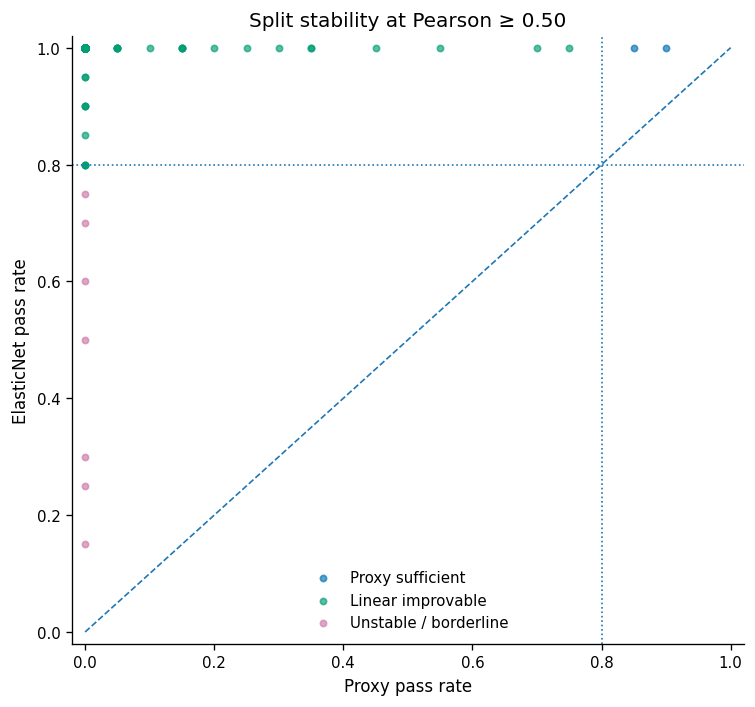

In [9]:
proxy_cols = [c for c in atlas.columns if c.startswith("proxy_")]
enet_cols = [c for c in atlas.columns if c.startswith("enet_")]
print("Proxy columns:", proxy_cols)
print("ENet columns:", enet_cols)

proxy_metric_col = f"proxy_median_{PRIMARY_METRIC}"
enet_metric_col = f"enet_median_{PRIMARY_METRIC}"
if proxy_metric_col not in atlas or enet_metric_col not in atlas:
    raise KeyError(f"Expected {proxy_metric_col} and {enet_metric_col} in atlas")

plot_df = atlas.dropna(subset=[proxy_metric_col, enet_metric_col]).copy()
plt.figure(figsize=(6.4, 6.0))
for cls in CLASS_ORDER:
    g = plot_df.loc[plot_df["robust_class"].eq(cls)]
    if g.empty:
        continue
    plt.scatter(
        g[proxy_metric_col], g[enet_metric_col], s=14, alpha=0.65,
        label=CLASS_LABELS.get(cls, cls), color=CLASS_COLORS.get(cls)
    )
low = min(plot_df[proxy_metric_col].min(), plot_df[enet_metric_col].min(), -0.1)
high = max(plot_df[proxy_metric_col].max(), plot_df[enet_metric_col].max(), 1.0)
plt.plot([low, high], [low, high], linestyle="--", linewidth=1)
plt.axvline(PRIMARY_THRESHOLD, linestyle=":", linewidth=1)
plt.axhline(PRIMARY_THRESHOLD, linestyle=":", linewidth=1)
plt.xlim(low, high)
plt.ylim(low, high)
plt.xlabel(f"Proxy median {PRIMARY_METRIC.title()}")
plt.ylabel(f"ElasticNet median {PRIMARY_METRIC.title()}")
plt.title("Protein-level performance: ElasticNet versus proxy")
plt.legend(frameon=False, loc="best")
plt.tight_layout()
save_current_figure("04_enet_vs_proxy_median_pearson")
plt.show()

# Pass-rate comparison.
plt.figure(figsize=(6.4, 6.0))
for cls in CLASS_ORDER:
    g = atlas.loc[atlas["robust_class"].eq(cls)].dropna(subset=["proxy_pass_rate", "enet_pass_rate"])
    if g.empty:
        continue
    plt.scatter(g["proxy_pass_rate"], g["enet_pass_rate"], s=14, alpha=0.65,
                label=CLASS_LABELS.get(cls, cls), color=CLASS_COLORS.get(cls))
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.axvline(PRIMARY_PASS_RATE, linestyle=":", linewidth=1)
plt.axhline(PRIMARY_PASS_RATE, linestyle=":", linewidth=1)
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.xlabel("Proxy pass rate")
plt.ylabel("ElasticNet pass rate")
plt.title(f"Split stability at {PRIMARY_METRIC.title()} ≥ {PRIMARY_THRESHOLD:.2f}")
plt.legend(frameon=False, loc="best")
plt.tight_layout()
save_current_figure("05_enet_vs_proxy_pass_rate")
plt.show()

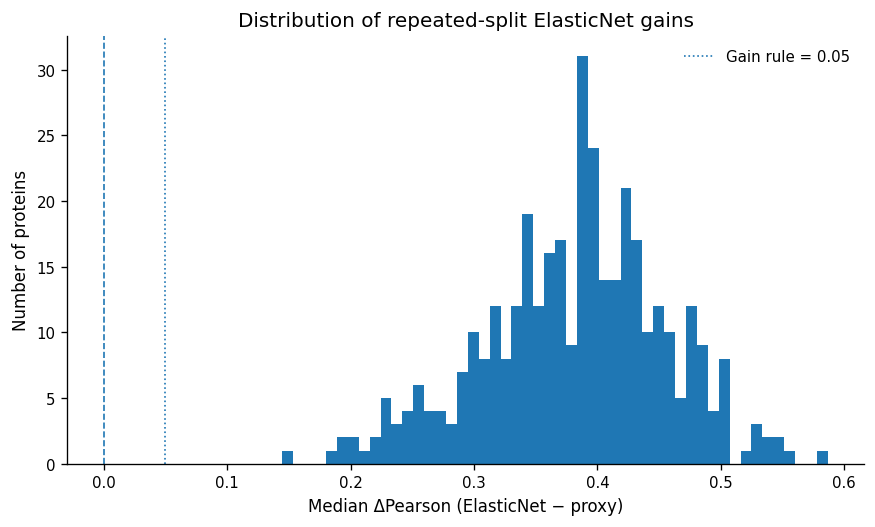

,statistic,n_proteins,fraction
0,proteins compared,369,1.0000
1,median gain > 0,369,1.0000
2,median gain >= 0.05,369,1.0000
3,gain CI lower bound > 0,369,1.0000
4,gain CI lower bound > 0.05,369,1.0000
5,gain positive in >=80% splits,369,1.0000


In [10]:
enet_gain = gains.loc[gains["comparison"].eq("enet_minus_proxy")].copy()
enet_gain = enet_gain.merge(atlas[["protein", "robust_class"]], on="protein", how="left")

plt.figure(figsize=(7.4, 4.5))
finite_gain = enet_gain["median_delta"].replace([np.inf, -np.inf], np.nan).dropna()
plt.hist(finite_gain, bins=50)
plt.axvline(0, linestyle="--", linewidth=1)
plt.axvline(GAIN_THRESHOLD, linestyle=":", linewidth=1, label=f"Gain rule = {GAIN_THRESHOLD:.2f}")
plt.xlabel(f"Median Δ{PRIMARY_METRIC.title()} (ElasticNet − proxy)")
plt.ylabel("Number of proteins")
plt.title("Distribution of repeated-split ElasticNet gains")
plt.legend(frameon=False)
plt.tight_layout()
save_current_figure("06_enet_minus_proxy_gain_distribution")
plt.show()

gain_summary = pd.DataFrame({
    "statistic": [
        "proteins compared",
        "median gain > 0",
        f"median gain >= {GAIN_THRESHOLD:.2f}",
        "gain CI lower bound > 0",
        f"gain CI lower bound > {GAIN_THRESHOLD:.2f}",
        "gain positive in >=80% splits",
    ],
    "n_proteins": [
        len(enet_gain),
        int((enet_gain["median_delta"] > 0).sum()),
        int((enet_gain["median_delta"] >= GAIN_THRESHOLD).sum()),
        int((enet_gain["ci_low"] > 0).sum()),
        int((enet_gain["ci_low"] > GAIN_THRESHOLD).sum()),
        int((enet_gain["fraction_delta_gt_0"] >= 0.80).sum()),
    ],
})
gain_summary["fraction"] = gain_summary["n_proteins"] / max(len(enet_gain), 1)
display(gain_summary)
gain_summary.to_csv(TABLE_DIR / "enet_gain_summary.tsv", sep="\t", index=False)

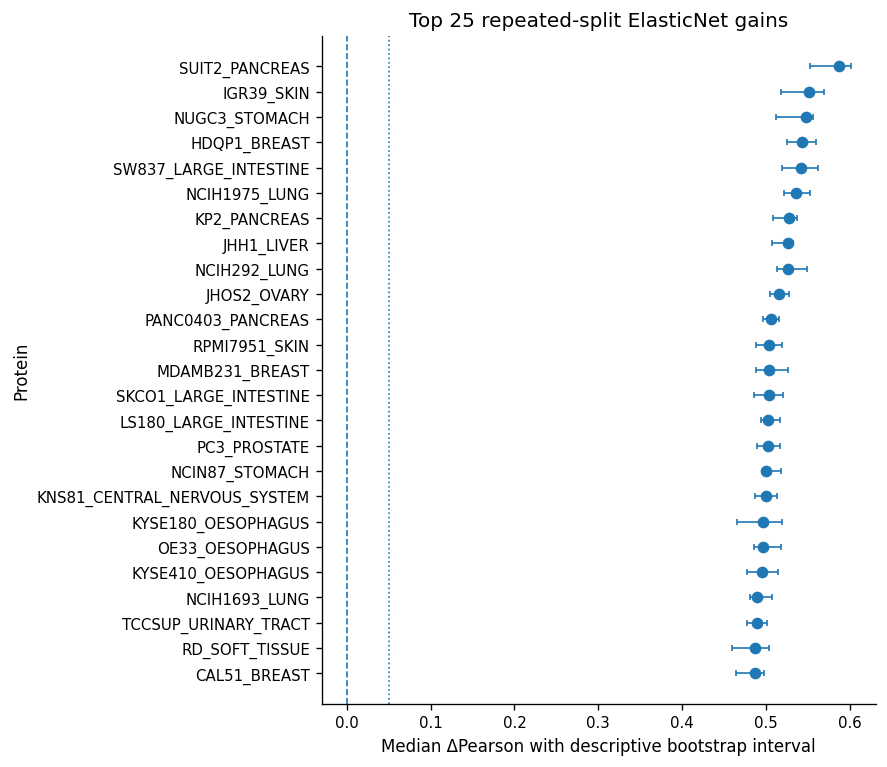

,protein,comparison,n_splits_valid,median_delta,ci_low,ci_high,fraction_delta_gt_0,robust_class
326,SUIT2_PANCREAS,enet_minus_proxy,20,0.5866,0.5525,0.6011,1.0000,robust_linear_improvable
123,IGR39_SKIN,enet_minus_proxy,20,0.5518,0.5178,0.5695,1.0000,robust_linear_improvable
255,NUGC3_STOMACH,enet_minus_proxy,20,0.5474,0.5119,0.5555,1.0000,robust_linear_improvable
88,HDQP1_BREAST,enet_minus_proxy,20,0.5427,0.5249,0.5600,1.0000,robust_linear_improvable
336,SW837_LARGE_INTESTINE,enet_minus_proxy,20,0.5422,0.5196,0.5622,1.0000,robust_linear_improvable
223,NCIH1975_LUNG,enet_minus_proxy,20,0.5358,0.5215,0.5519,1.0000,robust_linear_improvable
155,KP2_PANCREAS,enet_minus_proxy,20,0.5277,0.5089,0.5370,1.0000,robust_linear_improvable
130,JHH1_LIVER,enet_minus_proxy,20,0.5267,0.5068,0.5327,1.0000,robust_linear_improvable
237,NCIH292_LUNG,enet_minus_proxy,20,0.5258,0.5133,0.5489,1.0000,robust_linear_improvable
135,JHOS2_OVARY,enet_minus_proxy,20,0.5161,0.5049,0.5278,1.0000,robust_linear_improvable


In [11]:
# Forest plot of the strongest ElasticNet gains, requiring finite CIs.
top_gain = (
    enet_gain.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["median_delta", "ci_low", "ci_high"])
    .sort_values("median_delta", ascending=False)
    .head(TOP_N)
    .sort_values("median_delta")
)

if not top_gain.empty:
    y = np.arange(len(top_gain))
    x = top_gain["median_delta"].to_numpy()
    xerr = np.vstack([x - top_gain["ci_low"].to_numpy(), top_gain["ci_high"].to_numpy() - x])
    plt.figure(figsize=(7.5, max(5.0, 0.26 * len(top_gain))))
    plt.errorbar(x, y, xerr=xerr, fmt="o", capsize=2, linewidth=1)
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.axvline(GAIN_THRESHOLD, linestyle=":", linewidth=1)
    plt.yticks(y, top_gain["protein"])
    plt.xlabel(f"Median Δ{PRIMARY_METRIC.title()} with descriptive bootstrap interval")
    plt.ylabel("Protein")
    plt.title(f"Top {len(top_gain)} repeated-split ElasticNet gains")
    plt.tight_layout()
    save_current_figure("07_top_enet_gain_forest")
    plt.show()

top_gain.sort_values("median_delta", ascending=False).to_csv(TABLE_DIR / "top_enet_gains.tsv", sep="\t", index=False)
display(top_gain.sort_values("median_delta", ascending=False).head(15))

## 6. Per-split stability and sensitivity to a particular random partition

median_metric                                                  fraction_above_threshold                                                 
              count   mean    std    min    25%    50%    75%    max                    count   mean    std    min    25%    50%    75%    max
model                                                                                                                                         
enet        20.0000 0.7011 0.0085 0.6869 0.6931 0.7013 0.7083 0.7181                  20.0000 0.9867 0.0059 0.9756 0.9837 0.9864 0.9892 1.0000
proxy       20.0000 0.3150 0.0132 0.2904 0.3048 0.3173 0.3231 0.3419                  20.0000 0.0179 0.0114 0.0027 0.0081 0.0149 0.0251 0.0461

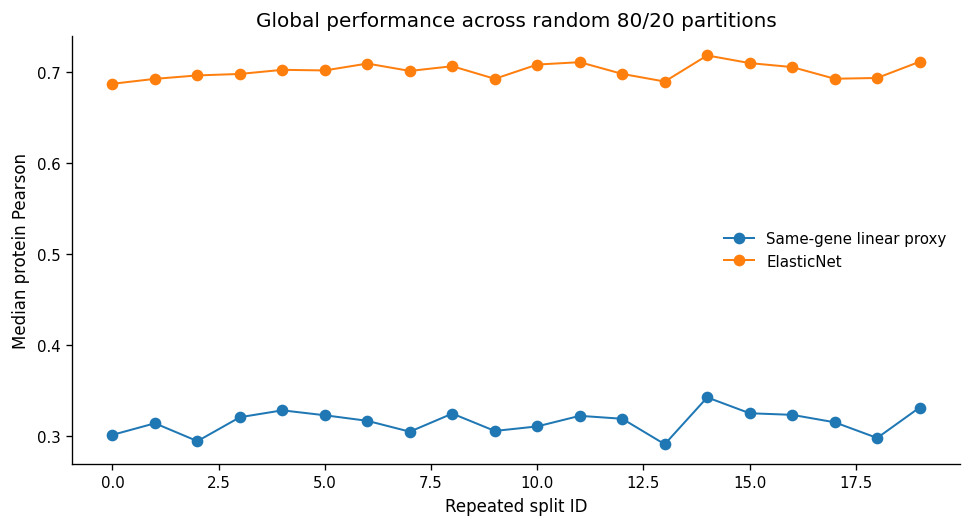

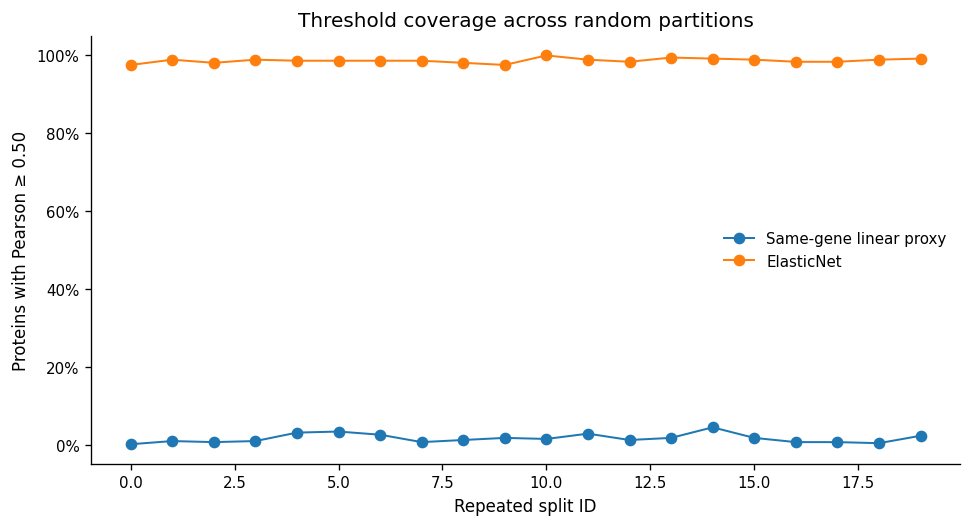

In [12]:
split_summary_rows = []
for label, frame in selected_frames.items():
    if frame.empty:
        continue
    for split_id, group in frame.groupby("split_id"):
        values = group[PRIMARY_METRIC].replace([np.inf, -np.inf], np.nan).dropna()
        split_summary_rows.append({
            "model": label,
            "split_id": int(split_id),
            "n_proteins": len(values),
            "median_metric": float(values.median()),
            "q25": float(values.quantile(0.25)),
            "q75": float(values.quantile(0.75)),
            "fraction_above_threshold": float((values >= PRIMARY_THRESHOLD).mean()),
        })
split_summary = pd.DataFrame(split_summary_rows)
display(split_summary.groupby("model")[["median_metric", "fraction_above_threshold"]].describe())
split_summary.to_csv(TABLE_DIR / "split_level_summary.tsv", sep="\t", index=False)

plt.figure(figsize=(8.2, 4.5))
for label, group in split_summary.groupby("model", sort=False):
    group = group.sort_values("split_id")
    plt.plot(group["split_id"], group["median_metric"], marker="o", linewidth=1.2, label=MODEL_LABELS.get(label, label))
plt.xlabel("Repeated split ID")
plt.ylabel(f"Median protein {PRIMARY_METRIC.title()}")
plt.title("Global performance across random 80/20 partitions")
plt.legend(frameon=False)
plt.tight_layout()
save_current_figure("08_split_level_median_performance")
plt.show()

plt.figure(figsize=(8.2, 4.5))
for label, group in split_summary.groupby("model", sort=False):
    group = group.sort_values("split_id")
    plt.plot(group["split_id"], group["fraction_above_threshold"], marker="o", linewidth=1.2, label=MODEL_LABELS.get(label, label))
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Repeated split ID")
plt.ylabel(f"Proteins with {PRIMARY_METRIC.title()} ≥ {PRIMARY_THRESHOLD:.2f}")
plt.title("Threshold coverage across random partitions")
plt.legend(frameon=False)
plt.tight_layout()
save_current_figure("09_split_level_threshold_coverage")
plt.show()

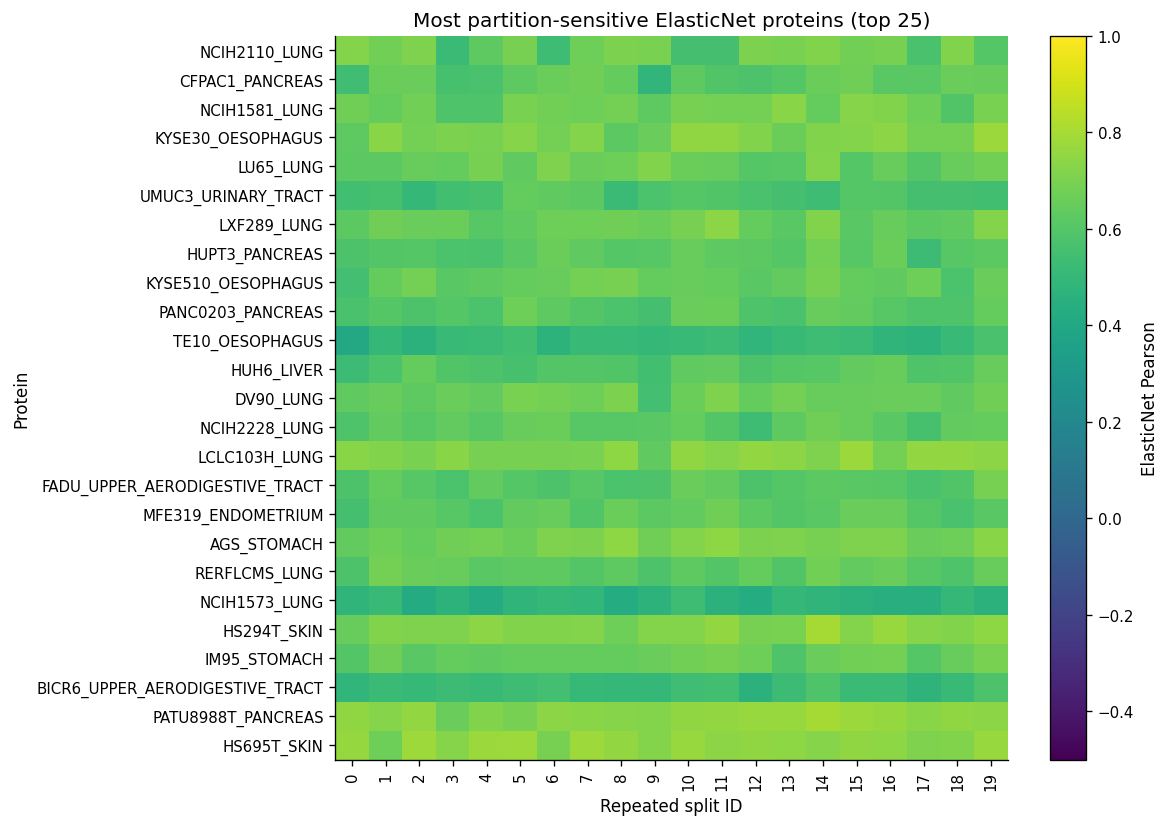

In [13]:
# Heatmap for proteins with the most variable ENet performance.
enet_frame = selected_frames.get("enet", pd.DataFrame())
if not enet_frame.empty:
    variability = enet_frame.groupby("protein")[PRIMARY_METRIC].agg(["median", "std", "count"])
    heat_proteins = variability.sort_values("std", ascending=False).head(TOP_N).index
    heat = enet_frame.loc[enet_frame["protein"].isin(heat_proteins)].pivot(index="protein", columns="split_id", values=PRIMARY_METRIC)
    heat = heat.loc[variability.loc[heat.index].sort_values("std", ascending=False).index]
    plt.figure(figsize=(10.0, max(5.0, 0.28 * len(heat))))
    image = plt.imshow(heat.to_numpy(), aspect="auto", interpolation="nearest", vmin=-0.5, vmax=1.0, cmap="viridis")
    plt.colorbar(image, label=f"ElasticNet {PRIMARY_METRIC.title()}")
    plt.xticks(np.arange(len(heat.columns)), heat.columns, rotation=90)
    plt.yticks(np.arange(len(heat.index)), heat.index)
    plt.xlabel("Repeated split ID")
    plt.ylabel("Protein")
    plt.title(f"Most partition-sensitive ElasticNet proteins (top {len(heat)})")
    plt.tight_layout()
    save_current_figure("10_partition_sensitive_enet_heatmap")
    plt.show()

## 7. Threshold and pass-rate sensitivity

The values 0.50 and 0.80 are useful operating points, but they are not laws of nature. This section recomputes the cascade over a grid of performance and stability thresholds. It uses the saved paired-gain intervals and therefore does not rerun training or bootstrap calculations.

,metric_threshold,pass_threshold,robust_class,n_proteins
0,0.3000,0.6000,robust_proxy_sufficient,199
1,0.3000,0.6000,robust_linear_improvable,170
2,0.3000,0.6000,robust_nonlinear_improvable,0
3,0.3000,0.6000,unstable_or_borderline,0
4,0.3000,0.6000,unresolved,0


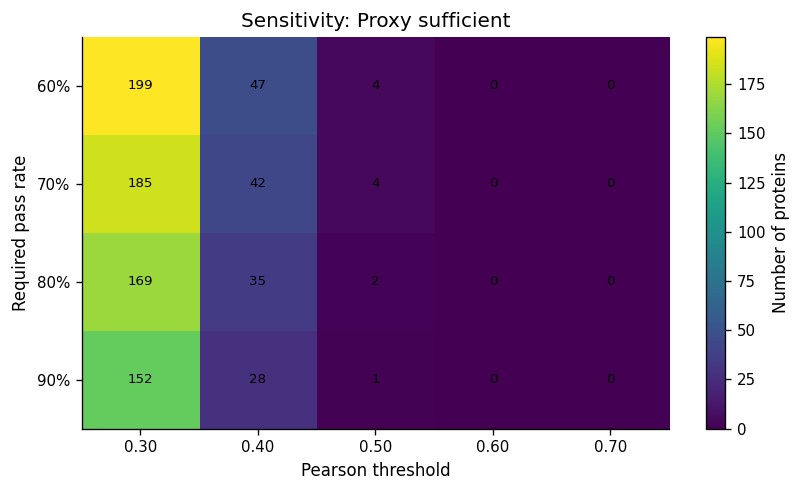

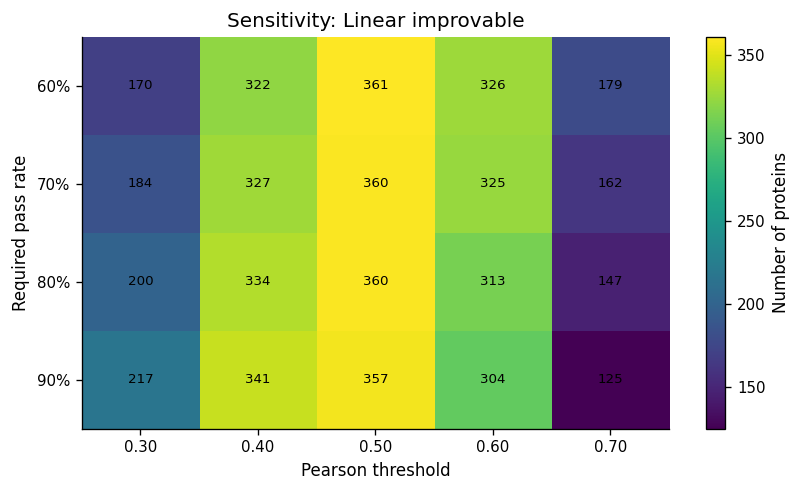

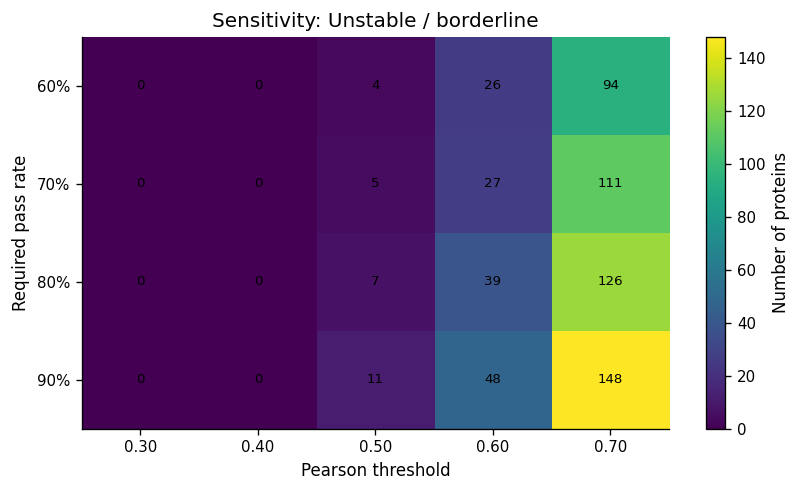

In [14]:
def build_sensitivity_classification(
    metrics_df: pd.DataFrame,
    gains_df: pd.DataFrame,
    metric_threshold: float,
    pass_threshold: float,
    gain_threshold: float,
) -> pd.DataFrame:
    summaries = []
    for label, config in [("proxy", PROXY_CONFIG), ("enet", ENET_CONFIG), ("xgb", XGB_CONFIG)]:
        if config is None:
            continue
        sub = select_config(metrics_df, config)
        if sub.empty:
            continue
        s = sub.groupby("protein")[PRIMARY_METRIC].agg(
            median_metric="median",
            n_valid=lambda x: np.isfinite(pd.to_numeric(x, errors="coerce")).sum(),
        ).reset_index()
        pass_rates = sub.groupby("protein")[PRIMARY_METRIC].apply(
            lambda x: np.nanmean(pd.to_numeric(x, errors="coerce") >= metric_threshold)
        ).rename("pass_rate").reset_index()
        s = s.merge(pass_rates, on="protein")
        s["model"] = label
        summaries.append(s)
    long = pd.concat(summaries, ignore_index=True)
    median_wide = long.pivot(index="protein", columns="model", values="median_metric")
    pass_wide = long.pivot(index="protein", columns="model", values="pass_rate")

    gain_enet = gains_df.loc[gains_df["comparison"].eq("enet_minus_proxy"), ["protein", "ci_low"]].rename(columns={"ci_low": "enet_gain_ci_low"}).set_index("protein")
    gain_xgb = gains_df.loc[gains_df["comparison"].eq("xgb_minus_enet"), ["protein", "ci_low"]].rename(columns={"ci_low": "xgb_gain_ci_low"}).set_index("protein")
    out = pd.DataFrame(index=pass_wide.index.union(median_wide.index)).join(pass_wide.add_suffix("_pass_rate")).join(median_wide.add_suffix("_median"))
    out = out.join(gain_enet, how="left").join(gain_xgb, how="left")

    classes = []
    for _, row in out.iterrows():
        proxy_good = row.get("proxy_pass_rate", np.nan) >= pass_threshold
        enet_good = row.get("enet_pass_rate", np.nan) >= pass_threshold
        xgb_good = row.get("xgb_pass_rate", np.nan) >= pass_threshold
        if proxy_good:
            cls = "robust_proxy_sufficient"
        elif enet_good and row.get("enet_gain_ci_low", np.nan) > gain_threshold:
            cls = "robust_linear_improvable"
        elif xgb_good and row.get("xgb_gain_ci_low", np.nan) > gain_threshold:
            cls = "robust_nonlinear_improvable"
        else:
            finite_pass = [v for v in [row.get("proxy_pass_rate", np.nan), row.get("enet_pass_rate", np.nan), row.get("xgb_pass_rate", np.nan)] if np.isfinite(v)]
            cls = "unstable_or_borderline" if finite_pass and max(finite_pass) > 0 else "unresolved"
        classes.append(cls)
    out["robust_class"] = classes
    return out.reset_index(names="protein")

metric_thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
pass_thresholds = [0.60, 0.70, 0.80, 0.90]
sensitivity_rows = []
for metric_threshold in metric_thresholds:
    for pass_threshold in pass_thresholds:
        classified = build_sensitivity_classification(metrics, gains, metric_threshold, pass_threshold, GAIN_THRESHOLD)
        vc = classified["robust_class"].value_counts()
        for cls in CLASS_ORDER:
            sensitivity_rows.append({
                "metric_threshold": metric_threshold,
                "pass_threshold": pass_threshold,
                "robust_class": cls,
                "n_proteins": int(vc.get(cls, 0)),
            })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(TABLE_DIR / "cascade_threshold_sensitivity.tsv", sep="\t", index=False)
display(sensitivity.head())

for cls in ["robust_proxy_sufficient", "robust_linear_improvable", "unstable_or_borderline"]:
    matrix = sensitivity.loc[sensitivity["robust_class"].eq(cls)].pivot(
        index="pass_threshold", columns="metric_threshold", values="n_proteins"
    )
    plt.figure(figsize=(7.0, 4.2))
    image = plt.imshow(matrix.to_numpy(), aspect="auto", interpolation="nearest", cmap="viridis")
    plt.colorbar(image, label="Number of proteins")
    plt.xticks(np.arange(len(matrix.columns)), [f"{x:.2f}" for x in matrix.columns])
    plt.yticks(np.arange(len(matrix.index)), [f"{x:.0%}" for x in matrix.index])
    plt.xlabel(f"{PRIMARY_METRIC.title()} threshold")
    plt.ylabel("Required pass rate")
    plt.title(f"Sensitivity: {CLASS_LABELS.get(cls, cls)}")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            plt.text(j, i, f"{int(matrix.iloc[i, j])}", ha="center", va="center", fontsize=8)
    plt.tight_layout()
    save_current_figure(f"11_sensitivity_{cls}")
    plt.show()

## 8. Calibration and absolute-error diagnostics

Correlation measures covariation, not numerical calibration. A model can have high Pearson correlation while compressing the prediction range or having a large absolute error. The following views should accompany the Pearson cascade.

,proteins,median_nrmse,median_r2,median_slope,median_sd_ratio
model,,,,,
enet,369,0.7146,0.4888,1.0463,0.6722
proxy,369,0.9500,0.0966,1.0069,0.3123


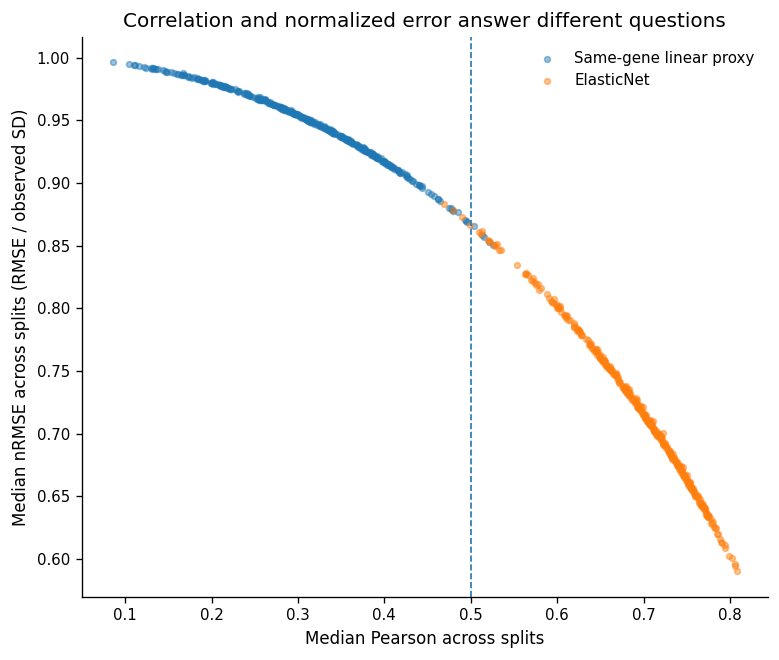

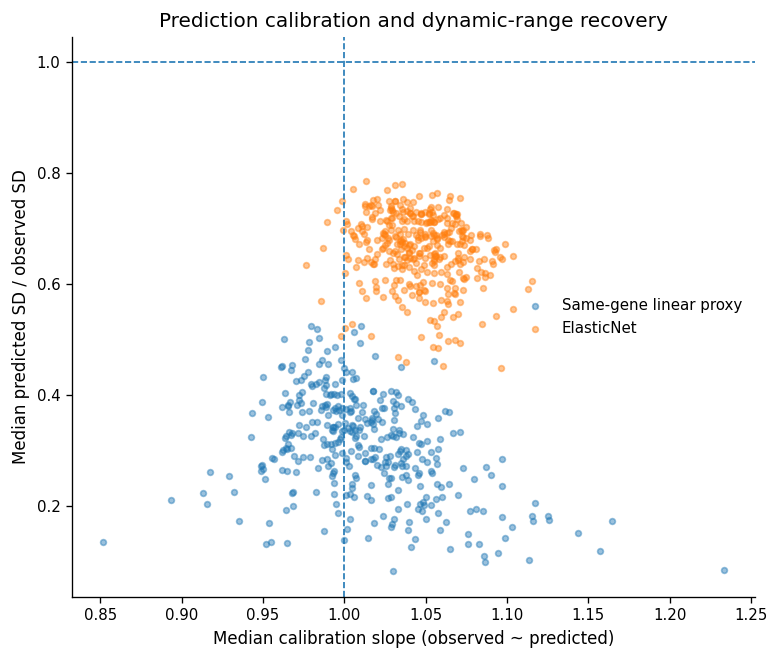

**High-correlation but potentially poorly calibrated rows:** 4

,protein,model,median_pearson,median_nrmse,median_r2,median_calibration_slope,median_calibration_intercept,median_sd_ratio
537,L33_PANCREAS,enet,0.5302,0.8513,0.2746,1.0636,-0.0137,0.4985
611,NCIH460_LUNG,enet,0.5282,0.8503,0.2763,1.0713,0.0054,0.4949
635,OVSAHO_OVARY,enet,0.5127,0.8619,0.2564,1.0547,0.0044,0.4867
585,NCIH1666_LUNG,enet,0.5115,0.8596,0.2603,1.0578,0.0111,0.4846


In [15]:
# Summarize calibration metrics per protein and model.
calibration_rows = []
for label, frame in selected_frames.items():
    if frame.empty:
        continue
    grouped = frame.groupby("protein")
    for protein, group in grouped:
        calibration_rows.append({
            "protein": protein,
            "model": label,
            "median_pearson": group["pearson"].median(),
            "median_nrmse": group["nrmse"].median(),
            "median_r2": group["r2"].median(),
            "median_calibration_slope": group["calibration_slope"].median(),
            "median_calibration_intercept": group["calibration_intercept"].median(),
            "median_sd_ratio": group["sd_ratio"].median(),
        })
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(TABLE_DIR / "per_protein_calibration_summary.tsv", sep="\t", index=False)
display(calibration.groupby("model").agg(
    proteins=("protein", "nunique"),
    median_nrmse=("median_nrmse", "median"),
    median_r2=("median_r2", "median"),
    median_slope=("median_calibration_slope", "median"),
    median_sd_ratio=("median_sd_ratio", "median"),
))

plt.figure(figsize=(6.6, 5.6))
for label, group in calibration.groupby("model", sort=False):
    plt.scatter(group["median_pearson"], group["median_nrmse"], s=12, alpha=0.45, label=MODEL_LABELS.get(label, label))
plt.axvline(PRIMARY_THRESHOLD, linestyle="--", linewidth=1)
plt.xlabel("Median Pearson across splits")
plt.ylabel("Median nRMSE across splits (RMSE / observed SD)")
plt.title("Correlation and normalized error answer different questions")
plt.legend(frameon=False)
plt.tight_layout()
save_current_figure("12_pearson_vs_nrmse")
plt.show()

plt.figure(figsize=(6.6, 5.6))
for label, group in calibration.groupby("model", sort=False):
    plt.scatter(group["median_calibration_slope"], group["median_sd_ratio"], s=12, alpha=0.45, label=MODEL_LABELS.get(label, label))
plt.axvline(1, linestyle="--", linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)
plt.xlabel("Median calibration slope (observed ~ predicted)")
plt.ylabel("Median predicted SD / observed SD")
plt.title("Prediction calibration and dynamic-range recovery")
plt.legend(frameon=False)
plt.tight_layout()
save_current_figure("13_calibration_slope_vs_sd_ratio")
plt.show()

# High-correlation but poorly calibrated proteins.
suspicious = calibration.loc[
    (calibration["median_pearson"] >= PRIMARY_THRESHOLD)
    & ((calibration["median_nrmse"] > 1.0) | (calibration["median_sd_ratio"] < 0.5) | (calibration["median_sd_ratio"] > 1.5))
].sort_values(["model", "median_pearson"], ascending=[True, False])
suspicious.to_csv(TABLE_DIR / "high_correlation_poor_calibration.tsv", sep="\t", index=False)
display(Markdown(f"**High-correlation but potentially poorly calibrated rows:** {len(suspicious):,}"))
display(suspicious.head(30))

## 9. ElasticNet hyperparameters and sparsity

Parsed hyperparameter columns: ['param_alpha', 'param_l1_ratio']


,param_alpha,param_l1_ratio,n_protein_splits
3,0.0100,0.5000,4625
4,0.0100,0.9000,1695
2,0.0100,0.1000,839
1,0.0010,0.9000,165
5,0.1000,0.1000,48
0,0.0010,0.5000,8


,count,mean,std,min,25%,50%,75%,max
n_selected_features,"7,380.0000",369.0000,0.0000,369.0000,369.0000,369.0000,369.0000,369.0000
n_nonzero_features,"7,380.0000",122.7955,66.2679,31.0000,80.0000,107.0000,131.0000,328.0000
best_cv_mse,"7,380.0000",0.3279,0.1704,0.0760,0.2178,0.2966,0.3854,1.6238


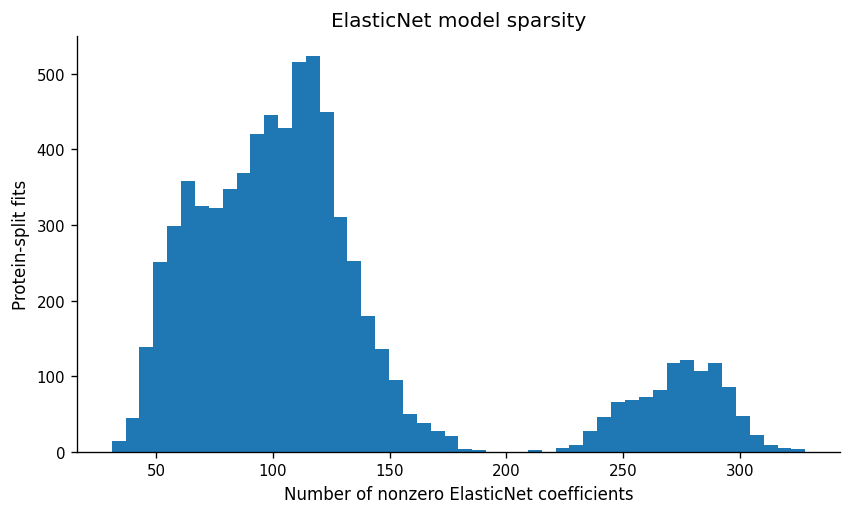

In [16]:
enet_rows = selected_frames.get("enet", pd.DataFrame()).copy()
if not enet_rows.empty:
    parsed_params = []
    for text in enet_rows.get("best_params_json", pd.Series(index=enet_rows.index, dtype=object)).fillna("{}"):
        try:
            parsed_params.append(json.loads(text))
        except Exception:
            parsed_params.append({})
    params_df = pd.json_normalize(parsed_params)
    params_df.index = enet_rows.index
    enet_with_params = pd.concat([enet_rows, params_df.add_prefix("param_")], axis=1)

    param_cols = [c for c in enet_with_params.columns if c.startswith("param_")]
    print("Parsed hyperparameter columns:", param_cols)
    if param_cols:
        param_frequency = (
            enet_with_params.groupby(param_cols, dropna=False).size()
            .reset_index(name="n_protein_splits")
            .sort_values("n_protein_splits", ascending=False)
        )
        display(param_frequency.head(20))
        param_frequency.to_csv(TABLE_DIR / "enet_hyperparameter_frequency.tsv", sep="\t", index=False)

    sparsity_summary = enet_with_params[["n_selected_features", "n_nonzero_features", "best_cv_mse"]].describe().T
    display(sparsity_summary)
    sparsity_summary.to_csv(TABLE_DIR / "enet_sparsity_summary.tsv", sep="\t")

    if "n_nonzero_features" in enet_with_params:
        plt.figure(figsize=(7.2, 4.4))
        plt.hist(enet_with_params["n_nonzero_features"].dropna(), bins=50)
        plt.xlabel("Number of nonzero ElasticNet coefficients")
        plt.ylabel("Protein-split fits")
        plt.title("ElasticNet model sparsity")
        plt.tight_layout()
        save_current_figure("14_enet_nonzero_coefficients")
        plt.show()

## 10. Priority protein tables for manual inspection and the manuscript

In [17]:
# Build a consolidated table with the most useful quantities.
priority = atlas.copy()
priority = priority.merge(
    enet_gain[["protein", "median_delta", "ci_low", "ci_high", "fraction_delta_gt_0"]].rename(columns={
        "median_delta": "enet_minus_proxy_median_delta_check",
        "ci_low": "enet_minus_proxy_ci_low_check",
        "ci_high": "enet_minus_proxy_ci_high_check",
        "fraction_delta_gt_0": "enet_minus_proxy_fraction_positive_check",
    }),
    on="protein", how="left"
)

priority.to_csv(TABLE_DIR / "robustness_master_table.tsv", sep="\t", index=False)

linear_improvable = priority.loc[priority["robust_class"].eq("robust_linear_improvable")].sort_values(
    "enet_vs_proxy_median_delta", ascending=False
)
unstable = priority.loc[priority["robust_class"].eq("unstable_or_borderline")].copy()
unresolved = priority.loc[priority["robust_class"].eq("unresolved")].copy()
proxy_sufficient = priority.loc[priority["robust_class"].eq("robust_proxy_sufficient")].sort_values(
    proxy_metric_col, ascending=False
)

for name, table in [
    ("robust_linear_improvable", linear_improvable),
    ("unstable_or_borderline", unstable),
    ("unresolved", unresolved),
    ("robust_proxy_sufficient", proxy_sufficient),
]:
    table.to_csv(TABLE_DIR / f"proteins_{name}.tsv", sep="\t", index=False)

print(f"Proxy sufficient:       {len(proxy_sufficient):,}")
print(f"Linear improvable:      {len(linear_improvable):,}")
print(f"Unstable / borderline: {len(unstable):,}")
print(f"Unresolved:             {len(unresolved):,}")

display(Markdown("### Strongest robust ElasticNet improvements"))
display(linear_improvable.head(30))
display(Markdown("### Unstable / borderline proteins"))
display(unstable.sort_values("enet_pass_rate", ascending=False).head(30))
display(Markdown("### Unresolved proteins"))
display(unresolved.head(30))

Proxy sufficient:       2
Linear improvable:      360
Unstable / borderline: 7
Unresolved:             0


### Strongest robust ElasticNet improvements

,protein,proxy_n_splits_valid,proxy_median_pearson,proxy_ci_low,proxy_ci_high,proxy_q25,proxy_q75,proxy_pass_rate,enet_n_splits_valid,enet_median_pearson,enet_ci_low,enet_ci_high,enet_q25,enet_q75,enet_pass_rate,enet_vs_proxy_n_splits_valid,enet_vs_proxy_median_delta,enet_vs_proxy_ci_low,enet_vs_proxy_ci_high,enet_vs_proxy_fraction_delta_gt_0,robust_class,threshold,pass_rate_rule,gain_threshold_rule,enet_minus_proxy_median_delta_check,enet_minus_proxy_ci_low_check,enet_minus_proxy_ci_high_check,enet_minus_proxy_fraction_positive_check
326,SUIT2_PANCREAS,20,0.1772,0.1466,0.1999,0.1415,0.2096,0.0000,20,0.7538,0.7389,0.7701,0.7364,0.7703,1.0000,20,0.5866,0.5525,0.6011,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5866,0.5525,0.6011,1.0000
123,IGR39_SKIN,20,0.1360,0.1038,0.1659,0.0976,0.1672,0.0000,20,0.6826,0.6671,0.6963,0.6663,0.6970,1.0000,20,0.5518,0.5178,0.5695,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5518,0.5178,0.5695,1.0000
255,NUGC3_STOMACH,20,0.2192,0.2015,0.2488,0.1950,0.2548,0.0000,20,0.7588,0.7438,0.7706,0.7415,0.7740,1.0000,20,0.5474,0.5119,0.5555,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5474,0.5119,0.5555,1.0000
88,HDQP1_BREAST,20,0.1349,0.1204,0.1667,0.1173,0.1708,0.0000,20,0.6848,0.6741,0.6919,0.6721,0.6940,1.0000,20,0.5427,0.5249,0.5600,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5427,0.5249,0.5600,1.0000
336,SW837_LARGE_INTESTINE,20,0.2190,0.2084,0.2346,0.2056,0.2371,0.0000,20,0.7516,0.7412,0.7709,0.7409,0.7864,1.0000,20,0.5422,0.5196,0.5622,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5422,0.5196,0.5622,1.0000
223,NCIH1975_LUNG,20,0.1989,0.1765,0.2209,0.1718,0.2284,0.0000,20,0.7322,0.7211,0.7459,0.7174,0.7492,1.0000,20,0.5358,0.5215,0.5519,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5358,0.5215,0.5519,1.0000
155,KP2_PANCREAS,20,0.2386,0.2040,0.2501,0.1984,0.2578,0.0000,20,0.7560,0.7345,0.7699,0.7345,0.7706,1.0000,20,0.5277,0.5089,0.5370,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5277,0.5089,0.5370,1.0000
130,JHH1_LIVER,20,0.2789,0.2699,0.2900,0.2685,0.2939,0.0000,20,0.8055,0.7953,0.8121,0.7939,0.8130,1.0000,20,0.5267,0.5068,0.5327,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5267,0.5068,0.5327,1.0000
237,NCIH292_LUNG,20,0.1486,0.1408,0.1616,0.1392,0.1667,0.0000,20,0.6774,0.6639,0.6875,0.6619,0.6886,1.0000,20,0.5258,0.5133,0.5489,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5258,0.5133,0.5489,1.0000
135,JHOS2_OVARY,20,0.2129,0.1951,0.2213,0.1858,0.2222,0.0000,20,0.7149,0.7087,0.7297,0.7075,0.7299,1.0000,20,0.5161,0.5049,0.5278,1.0000,robust_linear_improvable,0.5000,0.8000,0.0500,0.5161,0.5049,0.5278,1.0000


### Unstable / borderline proteins

,protein,proxy_n_splits_valid,proxy_median_pearson,proxy_ci_low,proxy_ci_high,proxy_q25,proxy_q75,proxy_pass_rate,enet_n_splits_valid,enet_median_pearson,enet_ci_low,enet_ci_high,enet_q25,enet_q75,enet_pass_rate,enet_vs_proxy_n_splits_valid,enet_vs_proxy_median_delta,enet_vs_proxy_ci_low,enet_vs_proxy_ci_high,enet_vs_proxy_fraction_delta_gt_0,robust_class,threshold,pass_rate_rule,gain_threshold_rule,enet_minus_proxy_median_delta_check,enet_minus_proxy_ci_low_check,enet_minus_proxy_ci_high_check,enet_minus_proxy_fraction_positive_check
21,BICR6_UPPER_AERODIGESTIVE_TRACT,20,0.1301,0.1191,0.1485,0.1175,0.1549,0.0000,20,0.5221,0.5075,0.5320,0.5049,0.5350,0.7500,20,0.3952,0.3659,0.4067,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3952,0.3659,0.4067,1.0000
216,NCIH1666_LUNG,20,0.2015,0.1786,0.2175,0.1651,0.2194,0.0000,20,0.5115,0.4998,0.5321,0.4934,0.5405,0.7000,20,0.3216,0.3014,0.3385,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3216,0.3014,0.3385,1.0000
343,TE10_OESOPHAGUS,20,0.1215,0.1041,0.1447,0.1020,0.1549,0.0000,20,0.5099,0.4940,0.5199,0.4868,0.5203,0.6000,20,0.3701,0.3475,0.3989,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3701,0.3475,0.3989,1.0000
29,CAL27_UPPER_AERODIGESTIVE_TRACT,20,0.1663,0.1490,0.1730,0.1461,0.1748,0.0000,20,0.4987,0.4783,0.5216,0.4707,0.5274,0.5000,20,0.3328,0.3230,0.3487,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3328,0.3230,0.3487,1.0000
107,HSC4_UPPER_AERODIGESTIVE_TRACT,20,0.1103,0.0859,0.1279,0.0844,0.1318,0.0000,20,0.4897,0.4799,0.5069,0.4797,0.5095,0.3000,20,0.3861,0.3675,0.4069,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3861,0.3675,0.4069,1.0000
275,RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,20,0.2651,0.2447,0.2738,0.2411,0.2780,0.0000,20,0.4795,0.4693,0.4948,0.4672,0.4992,0.2500,20,0.2235,0.2012,0.2349,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.2235,0.2012,0.2349,1.0000
213,NCIH1573_LUNG,20,0.1438,0.1185,0.1524,0.1172,0.1533,0.0000,20,0.4690,0.4555,0.4881,0.4468,0.4935,0.1500,20,0.3262,0.3151,0.3356,1.0000,unstable_or_borderline,0.5000,0.8000,0.0500,0.3262,0.3151,0.3356,1.0000


### Unresolved proteins

,protein,proxy_n_splits_valid,proxy_median_pearson,proxy_ci_low,proxy_ci_high,proxy_q25,proxy_q75,proxy_pass_rate,enet_n_splits_valid,enet_median_pearson,enet_ci_low,enet_ci_high,enet_q25,enet_q75,enet_pass_rate,enet_vs_proxy_n_splits_valid,enet_vs_proxy_median_delta,enet_vs_proxy_ci_low,enet_vs_proxy_ci_high,enet_vs_proxy_fraction_delta_gt_0,robust_class,threshold,pass_rate_rule,gain_threshold_rule,enet_minus_proxy_median_delta_check,enet_minus_proxy_ci_low_check,enet_minus_proxy_ci_high_check,enet_minus_proxy_fraction_positive_check


## 11. Optional prediction-level inspection

This section runs only if the original training used `KEEP_PREDICTIONS=1` and prediction shards or compressed prediction cubes are available. It enables direct observed-versus-predicted plots for individual proteins. If predictions were not saved, the section explains what is missing rather than failing.

In [18]:
prediction_cube_dir = RESULTS_DIR / "prediction_cubes"
prediction_shard_dir = RESULTS_DIR / "prediction_shards"

cube_files = sorted(prediction_cube_dir.glob("*.npz")) if prediction_cube_dir.exists() else []
shard_files = sorted(prediction_shard_dir.rglob("*_pred.parquet")) if prediction_shard_dir.exists() else []
shard_files += sorted(prediction_shard_dir.rglob("*_pred.csv.gz")) if prediction_shard_dir.exists() else []

print(f"Compressed prediction cubes: {len(cube_files)}")
print(f"Prediction shard files:      {len(shard_files)}")

if not cube_files and not shard_files:
    display(Markdown(
        "Predictions were not saved for this run (`KEEP_PREDICTIONS=0`). "
        "All split-level statistical summaries remain available, but observed-versus-predicted sample plots and sample-level paired resampling cannot be reconstructed from metrics alone."
    ))
else:
    display(Markdown(
        "Prediction files are available. For a compact reusable cube, rerun `run_after_jobs.sh` with `COMBINE_PREDICTIONS=1`, then load the `.npz` file here."
    ))

Compressed prediction cubes: 0
Prediction shard files:      0


Predictions were not saved for this run (`KEEP_PREDICTIONS=0`). All split-level statistical summaries remain available, but observed-versus-predicted sample plots and sample-level paired resampling cannot be reconstructed from metrics alone.

## 12. Automatically generated interpretation summary

In [19]:
def fmt_metric(value: float) -> str:
    return "NA" if not np.isfinite(value) else f"{value:.3f}"

count_map = class_counts.set_index("robust_class")["n_proteins"].to_dict()
fraction_map = class_counts.set_index("robust_class")["fraction"].to_dict()
proxy_n = count_map.get("robust_proxy_sufficient", 0)
linear_n = count_map.get("robust_linear_improvable", 0)
unstable_n = count_map.get("unstable_or_borderline", 0)
unresolved_n = count_map.get("unresolved", 0)
total_n = int(class_counts["n_proteins"].sum())

proxy_median = protein_summaries.get("proxy", pd.DataFrame()).get(f"{PRIMARY_METRIC}_median", pd.Series(dtype=float)).median()
enet_median = protein_summaries.get("enet", pd.DataFrame()).get(f"{PRIMARY_METRIC}_median", pd.Series(dtype=float)).median()
median_gain = enet_gain["median_delta"].median()
strict_gain_n = int((enet_gain["ci_low"] > GAIN_THRESHOLD).sum())

summary_text = f"""
### Descriptive result summary

- The analysis contains **{total_n:,} proteins** evaluated over **{expected_splits} repeated 80/20 splits**.
- At Pearson ≥ **{PRIMARY_THRESHOLD:.2f}**, required in at least **{PRIMARY_PASS_RATE:.0%}** of splits, **{proxy_n:,} ({fraction_map.get('robust_proxy_sufficient', 0):.1%})** proteins were classified as proxy-sufficient and **{linear_n:,} ({fraction_map.get('robust_linear_improvable', 0):.1%})** as robustly linear-improvable.
- **{unstable_n:,} ({fraction_map.get('unstable_or_borderline', 0):.1%})** proteins were unstable or borderline, and **{unresolved_n:,} ({fraction_map.get('unresolved', 0):.1%})** were unresolved under the saved rule.
- The median of the per-protein median Pearson values was **{fmt_metric(proxy_median)}** for the proxy and **{fmt_metric(enet_median)}** for ElasticNet.
- The median repeated-split ElasticNet-minus-proxy gain was **{fmt_metric(median_gain)}**. The descriptive gain interval lower bound exceeded **{GAIN_THRESHOLD:.2f}** for **{strict_gain_n:,}** proteins.

### Recommended wording for the manuscript

> Across {expected_splits} repeated 80/20 partitions of CCLE, we quantified protein-level stability using the median and interquartile range of held-out Pearson correlations and the fraction of partitions exceeding a prespecified correlation threshold. At Pearson ≥ {PRIMARY_THRESHOLD:.2f} in at least {PRIMARY_PASS_RATE:.0%} of partitions, {proxy_n:,} proteins were consistently captured by a fitted same-gene RNA proxy, whereas {linear_n:,} additional proteins were consistently captured by ElasticNet and showed a descriptive median gain of at least {GAIN_THRESHOLD:.2f} whose split-level bootstrap lower bound also exceeded that value.

### Required caveat

> Repeated holdout test sets overlap, and the bootstrap intervals summarize the empirical distribution across repeated partitions rather than independent experimental replicates. We therefore interpret this analysis as a stability assessment and use full-sample out-of-fold and external-cohort evaluations for primary inferential and transfer claims.
"""
display(Markdown(summary_text))

with open(INSPECTION_DIR / "automatic_interpretation.md", "w", encoding="utf-8") as handle:
    handle.write(summary_text)
print(f"Saved interpretation: {INSPECTION_DIR / 'automatic_interpretation.md'}")


### Descriptive result summary

- The analysis contains **369 proteins** evaluated over **20 repeated 80/20 splits**.
- At Pearson ≥ **0.50**, required in at least **80%** of splits, **2 (0.5%)** proteins were classified as proxy-sufficient and **360 (97.6%)** as robustly linear-improvable.
- **7 (1.9%)** proteins were unstable or borderline, and **0 (0.0%)** were unresolved under the saved rule.
- The median of the per-protein median Pearson values was **0.312** for the proxy and **0.702** for ElasticNet.
- The median repeated-split ElasticNet-minus-proxy gain was **0.387**. The descriptive gain interval lower bound exceeded **0.05** for **369** proteins.

### Recommended wording for the manuscript

> Across 20 repeated 80/20 partitions of CCLE, we quantified protein-level stability using the median and interquartile range of held-out Pearson correlations and the fraction of partitions exceeding a prespecified correlation threshold. At Pearson ≥ 0.50 in at least 80% of partitions, 2 proteins were consistently captured by a fitted same-gene RNA proxy, whereas 360 additional proteins were consistently captured by ElasticNet and showed a descriptive median gain of at least 0.05 whose split-level bootstrap lower bound also exceeded that value.

### Required caveat

> Repeated holdout test sets overlap, and the bootstrap intervals summarize the empirical distribution across repeated partitions rather than independent experimental replicates. We therefore interpret this analysis as a stability assessment and use full-sample out-of-fold and external-cohort evaluations for primary inferential and transfer claims.


Saved interpretation: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\06.robustness\results\inspection\automatic_interpretation.md


## 13. Final checklist

Before using the results in the paper, verify:

1. Every selected model has the expected number of proteins and 20 valid splits per protein, or missingness is explicitly reported.
2. Failed/constant fits are rare and not concentrated in one cascade class.
3. The exact configuration in this notebook matches the configuration passed to `run_after_jobs.sh`.
4. Cascade conclusions remain qualitatively similar across Pearson thresholds 0.30/0.50/0.70 and pass-rate requirements 60/70/80/90%.
5. High-correlation proteins are not automatically described as calibrated; inspect nRMSE, calibration slope, and SD ratio.
6. The split-level bootstrap is described as descriptive stability, not as an independent-sample inferential test.
7. XGBoost is added only after the ENet unresolved/borderline set is defined, unless full-protein XGBoost compute is justified.
8. Main biological claims are confirmed in lineage-held-out and external-cohort analyses.